# 🧴 BottleCap Checker — Day 23 / 100 | Research-grade YOLOv8 Notebook

**Industrial bottle-cap quality inspection** · source-audited · leakage-aware · held-out evaluation · reproducible artifact release

| Track | Data | Task | Rule |
|---|---|---|---|
| **Primary** | Bottle Defects v28 | 5-class bottle-cap object detection | Train/val/test **as published**, model selection on **val**, final report on **test** |
| **Secondary (optional)** | Dataset of Packaging | Separate 4-class packaging detection experiment | **Never merge classes**; activate only after audits |

**No fabricated scores.** All displayed metrics and artifacts must come from actual execution. Dataset provenance: uploaded Kaggle mount (`loliwibu/bottlecap-checker-day23-datasets`). The primary Roboflow `data.yaml` labels are **Broken Cap, Broken Ring, Good Cap, Loose Cap, No Cap**. Uploaded source cites CC BY 4.0; confirm attribution in your portfolio. The secondary dataset license is **not established** in this notebook.

**Safety:** Example detections are decision support, not an industrial acceptance certification. **Do not run inference on unknown `.pt` files**; load only trusted checkpoints. Training uses the published primary train/val split. Source test is touched only after checkpoint selection.

**Output:** `/kaggle/working/bottlecap_day23/` and `/kaggle/working/BottleCap_Day23_Research_Artifacts.zip`.

## 00 · Environment and execution policy
GPU T4 or P100 recommended. **Do not call Save Version / Run All until the audit cells pass.** The optional secondary training defaults to `False`. Internet may be needed once for `yolov8n.pt` and `ultralytics`.

In [1]:
import sys, os, json, re, time, hashlib, shutil, random, warnings, subprocess, importlib.util
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MOUNT = Path('/kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets')
OUT = Path('/kaggle/working/bottlecap_day23')
REPORT = OUT/'reports'; PLOTS=OUT/'plots'; MODELS=OUT/'models'; RUNS=OUT/'runs'; STAGE=OUT/'staged'
for d in (OUT,REPORT,PLOTS,MODELS,RUNS,STAGE): d.mkdir(parents=True,exist_ok=True)
CFG = dict(seed=42, model='yolov8n.pt', epochs=65, patience=15, imgsz=640, batch=16,
           workers=2, secondary_train=False, secondary_epochs=45, export_onnx=True,
           test_conf=0.25, max_examples=12, require_primary_zero_cross_split_hash=True)
print('Python:',sys.version.split()[0], '| Torch:',torch.__version__, '| CUDA:',torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))
if not MOUNT.exists(): raise FileNotFoundError(f'Kaggle input missing: {MOUNT}. Attach your dataset under Add Input.')
print('Mount:',MOUNT)
(REPORT/'environment.json').write_text(json.dumps(dict(python=sys.version,torch=torch.__version__,cuda=torch.cuda.is_available(),cfg=CFG,input=str(MOUNT)),indent=2,default=str))

Python: 3.13.15 | Torch: 2.11.0+cu128 | CUDA: True
GPU: Tesla T4
Mount: /kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets


520

## 01 · Dataset discovery (actual mounted folders, no guesswork)
Kaggle may auto-unpack uploaded ZIPs and may add nesting, so detect each **data.yaml** by its declared class ontology and **validate its actual train/valid/test directories**. No hard-coded path to an assumed extraction layout.

In [2]:
import yaml
IMAGE_EXT={'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
all_yamls=sorted([p for p in MOUNT.rglob('*') if p.is_file() and p.name.lower() in ('data.yaml','dataset.yaml')])
print('YAML candidates:',[(str(p.relative_to(MOUNT))) for p in all_yamls])
if not all_yamls:
    print('Top-level entries:',[(p.name,p.is_dir()) for p in MOUNT.iterdir()])
    raise RuntimeError('No data.yaml found; Kaggle has not unpacked the images/labels or the wrong input is mounted.')

def parse_names(y):
    names=y.get('names',[])
    if isinstance(names,dict): names=[names[k] for k in sorted(names,key=lambda k:int(k))]
    return [str(n).strip() for n in names]

def locate_images(root,declared,split_name):
    # Resolve either root/train/images or root/valid/images; distrust absolute YAML paths from exporter.
    candidates=[root/split_name/'images']
    if declared:
        s=str(declared).replace(chr(92),'/')
        parts=Path(s).parts
        if len(parts)>=2 and parts[-1]=='images':
            candidates.insert(0,root/parts[-2]/'images')
        p=Path(s)
        if not p.is_absolute(): candidates.append((root/p).resolve())
    for p in candidates:
        if p.is_dir() and any(f.suffix.lower() in IMAGE_EXT for f in p.iterdir() if f.is_file()):
            return p
    return None

def describe_dataset(yaml_path):
    y=yaml.safe_load(yaml_path.read_text(encoding='utf-8-sig'))
    names=parse_names(y); root=yaml_path.parent
    splits={s:locate_images(root,y.get('val' if s=='valid' else s),s) for s in ('train','valid','test')}
    # Some sources call validation folder val rather than valid.
    if splits['valid'] is None: splits['valid']=locate_images(root,y.get('val'),'val')
    return dict(root=root,source_yaml=yaml_path,config=y,names=names,splits=splits)

all_sources=[describe_dataset(p) for p in all_yamls]
for d in all_sources:
    print('\nSOURCE:',d['source_yaml'].relative_to(MOUNT),'\nclasses:',d['names'],
          '\nimages:',{s:(str(p) if p else None) for s,p in d['splits'].items()})
PRIMARY_NAMES=['Broken Cap','Broken Ring','Good Cap','Loose Cap','No Cap']
SECONDARY_NAMES=['Cap','Missing','Wrong bottle','box']
primary_candidates=[d for d in all_sources if d['names']==PRIMARY_NAMES]
secondary_candidates=[d for d in all_sources if d['names']==SECONDARY_NAMES]
if len(primary_candidates)!=1:
    raise RuntimeError(f'Expected exactly one primary 5-class source, found {len(primary_candidates)}. Review the printed YAML discovery.')
PRIMARY=primary_candidates[0]
if not all(PRIMARY['splits'][s] is not None for s in ('train','valid','test')):
    raise RuntimeError('Primary train/valid/test image directories are incomplete. Stop before training.')
SECONDARY=secondary_candidates[0] if len(secondary_candidates)==1 else None
print('\nPRIMARY ROOT VERIFIED:',PRIMARY['root'])
print('SECONDARY ROOT:',SECONDARY['root'] if SECONDARY else 'none (optional)')
(REPORT/'source_discovery.json').write_text(json.dumps([dict(root=str(d['root']),yaml=str(d['source_yaml']),classes=d['names'],splits={k:str(v) if v else None for k,v in d['splits'].items()}) for d in all_sources],indent=2))

YAML candidates: ['Bottle Defects.v28i.yolov8/data.yaml', 'Dataset of Packaging Defects and Associated Cost o/Dataset of Packaging Defects and Associated Cost o/Dataset of Packaging/Dataset of Packaging/data.yaml']

SOURCE: Bottle Defects.v28i.yolov8/data.yaml 
classes: ['Broken Cap', 'Broken Ring', 'Good Cap', 'Loose Cap', 'No Cap'] 
images: {'train': '/kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8/train/images', 'valid': '/kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8/valid/images', 'test': '/kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8/test/images'}

SOURCE: Dataset of Packaging Defects and Associated Cost o/Dataset of Packaging Defects and Associated Cost o/Dataset of Packaging/Dataset of Packaging/data.yaml 
classes: ['Cap', 'Missing', 'Wrong bottle', 'box'] 
images: {'train': '/kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Datas

2034

## 02 · Source contracts and image/annotation audit
Parse **every image and label**, check one-to-one pairing, valid class IDs, normalized finite xywh, image readability and exact content hashes. `ready_for_modeling` requires no missing/orphan/bad annotations. For a zero-object source image, an empty label file is permitted. No silent re-labeling.

In [3]:
def sha256_file(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def src_files(d):
    rows=[];bad=[];counts=Counter();classes=Counter();origins=defaultdict(list)
    for split,folder in d['splits'].items():
        if folder is None:continue
        labels_dir=folder.parent/'labels'
        imgs=sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXT)
        labs=sorted(p for p in labels_dir.glob('*.txt')) if labels_dir.exists() else []
        bystem={p.stem:p for p in labs}
        image_stems={p.stem for p in imgs}
        for lb in labs:
            if lb.stem not in image_stems:bad.append(dict(split=split,issue='orphan_label',file=str(lb)))
        for image in imgs:
            label=bystem.get(image.stem)
            if label is None: bad.append(dict(split=split,issue='missing_label',file=str(image))); continue
            try:
                with Image.open(image) as im:
                    im.verify()
                boxes=[]
                for line_num,line in enumerate(label.read_text(encoding='utf-8-sig').splitlines(),1):
                    if not line.strip():continue
                    parts=line.split()
                    if len(parts)!=5:raise ValueError(f'line {line_num}: expected 5 fields, got {len(parts)}')
                    cls=int(parts[0]); coords=[float(x) for x in parts[1:]]
                    if not (0<=cls<len(d['names'])):raise ValueError(f'line {line_num}: class {cls} out of range')
                    if not all(np.isfinite(coords)) or not all(0<=x<=1 for x in coords):raise ValueError(f'line {line_num}: invalid normalized xywh')
                    if coords[2]<=0 or coords[3]<=0:raise ValueError(f'line {line_num}: nonpositive width/height')
                    if abs(coords[0]-0.5)*2+coords[2] > 1+1e-3 or abs(coords[1]-0.5)*2+coords[3] > 1+1e-3:raise ValueError(f'line {line_num}: box exceeds image bounds')
                    boxes.append((cls,*coords));classes[cls]+=1
                digest=sha256_file(image)
                origins[digest].append(split)
                counts[split]+=1
                rows.append(dict(split=split,image=str(image),label=str(label),stem=image.stem,sha256=digest,box_count=len(boxes),class_ids=sorted({b[0] for b in boxes})))
            except Exception as exc:
                bad.append(dict(split=split,issue='unreadable_or_invalid',file=str(image),detail=str(exc)))
    cross={sha:sorted(set(s)) for sha,s in origins.items() if len(set(s))>1}
    summary=dict(source=str(d['root']),classes=d['names'],images_checked=len(rows),split_images=dict(counts),box_counts={d['names'][i]:v for i,v in classes.items()},invalid_count=len(bad),invalid_examples=bad[:40],cross_split_exact_duplicate_hash_count=len(cross),cross_split_hash_examples=list(cross.items())[:10])
    return pd.DataFrame(rows),summary

primary_rows,primary_audit=src_files(PRIMARY)
print(json.dumps(primary_audit,indent=2,ensure_ascii=False))
primary_rows.to_csv(REPORT/'primary_manifest.csv',index=False)
(REPORT/'primary_audit.json').write_text(json.dumps(primary_audit,indent=2,ensure_ascii=False))
if primary_audit['invalid_count']:
    raise RuntimeError(f'Primary dataset has {primary_audit["invalid_count"]} invalid files; inspect reports/primary_audit.json. No training.')
if primary_audit['cross_split_exact_duplicate_hash_count'] and CFG['require_primary_zero_cross_split_hash']:
    raise RuntimeError('Exact duplicate image hashes cross train/val/test boundaries; inspect primary audit and repair source split before training.')
expected={'train':398,'valid':113,'test':112}
if primary_audit['split_images']!=expected:
    warnings.warn(f'Dataset split counts differ from prior local audit: {primary_audit["split_images"]} vs {expected}. Review provenance; source version may differ.')
print('PRIMARY STRUCTURAL AUDIT PASSED')

{
  "source": "/kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8",
  "classes": [
    "Broken Cap",
    "Broken Ring",
    "Good Cap",
    "Loose Cap",
    "No Cap"
  ],
  "images_checked": 623,
  "split_images": {
    "train": 398,
    "valid": 113,
    "test": 112
  },
  "box_counts": {
    "Broken Ring": 66,
    "Loose Cap": 158,
    "Broken Cap": 63,
    "Good Cap": 218,
    "No Cap": 161
  },
  "invalid_count": 0,
  "invalid_examples": [],
  "cross_split_exact_duplicate_hash_count": 0,
  "cross_split_hash_examples": []
}
PRIMARY STRUCTURAL AUDIT PASSED


## 03 · Near-duplicate / augmentation-family risk
Exact SHA-256 is necessary but **not sufficient** to rule out augmented or near-identical images. Roboflow-style `.rf.<hex>` suffixes are removed to detect repeated source filename families across partitions; this is conservative (filenames can also collide). Any cross-split family collisions **stop training** until manually reviewed. This also prevents optimistic held-out claims from sibling augmentations.

In [4]:
def image_family(stem):
    s=re.sub(r'\.rf\.[0-9a-f]+$','',stem,flags=re.I)
    s=re.sub(r'([_-](?:flip|rot|aug|copy)[_-]?\d*)$','',s,flags=re.I)
    return s.lower()
primary_rows['family']=primary_rows['stem'].map(image_family)
family_splits=primary_rows.groupby('family')['split'].agg(lambda x:sorted(set(x))).to_dict()
cross_family={k:v for k,v in family_splits.items() if len(v)>1}
family_audit={'unique_families':len(family_splits),'cross_split_family_count':len(cross_family),'examples':list(cross_family.items())[:40], 'note':'Filename family heuristic; does not rule out visually similar scenes with unrelated names.'}
(REPORT/'primary_family_audit.json').write_text(json.dumps(family_audit,indent=2))
print(json.dumps(family_audit,indent=2))
if cross_family:raise RuntimeError('Filename families cross primary splits. Inspect primary_family_audit.json. Do not train until audited.')

{
  "unique_families": 623,
  "cross_split_family_count": 0,
  "examples": [],
  "note": "Filename family heuristic; does not rule out visually similar scenes with unrelated names."
}


## 04 · Secondary data audit — never merge label spaces
Source 2 has different classes (`Cap`, `Missing`, `Wrong bottle`, `box`) and a previously observed 8,139 images / 9,651 label files. Validate it as a **separate task only**. Report any unmatched labels; keep `secondary_train=False` unless the dataset is structurally valid and its provenance/license accepted. A secondary model is **not** evidence of better primary bottle-cap performance.

In [5]:
secondary_rows=None; secondary_audit={'status':'not_found_or_ambiguous','candidate_count':len(secondary_candidates)}
if SECONDARY:
    secondary_rows,secondary_audit=src_files(SECONDARY)
    secondary_rows.to_csv(REPORT/'secondary_manifest.csv',index=False)
    # The second dataset is not required to pass for primary modeling.
    print('SECONDARY AUDIT:',json.dumps(secondary_audit,indent=2,ensure_ascii=False)[:5000])
else:
    print('Secondary dataset not uniquely discovered; primary training remains independent.')
(REPORT/'secondary_audit.json').write_text(json.dumps(secondary_audit,indent=2,ensure_ascii=False))

SECONDARY AUDIT: {
  "source": "/kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Dataset of Packaging Defects and Associated Cost o/Dataset of Packaging Defects and Associated Cost o/Dataset of Packaging/Dataset of Packaging",
  "classes": [
    "Cap",
    "Missing",
    "Wrong bottle",
    "box"
  ],
  "images_checked": 0,
  "split_images": {},
  "box_counts": {},
  "invalid_count": 9651,
  "invalid_examples": [
    {
      "split": "train",
      "issue": "orphan_label",
      "file": "/kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Dataset of Packaging Defects and Associated Cost o/Dataset of Packaging Defects and Associated Cost o/Dataset of Packaging/Dataset of Packaging/train/labels/WIN_20240221_11_48_03_Pro_jpg.rf.2e740ef97859930babb7542d444acb49.txt"
    },
    {
      "split": "train",
      "issue": "orphan_label",
      "file": "/kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Dataset of Packaging Defects and Associated Cost o

15575

## 05 · EDA: split volume, object balance, and qualitative ground truth

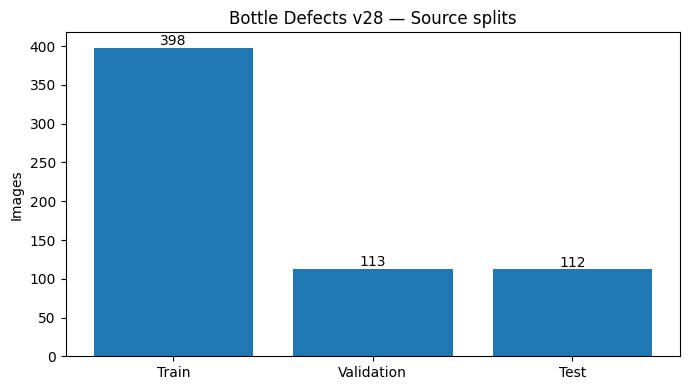

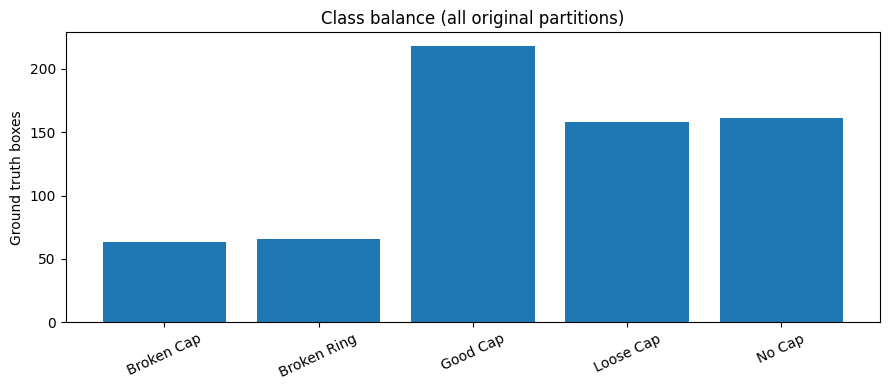

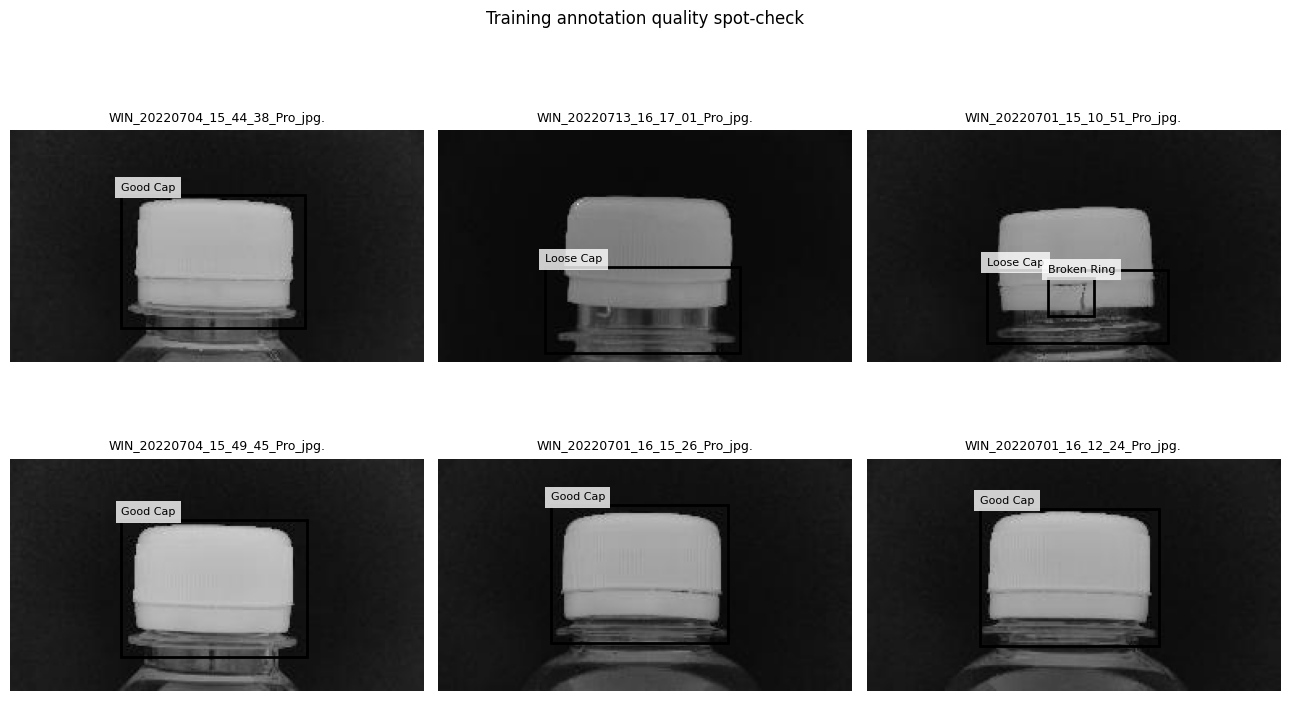

In [6]:
from matplotlib.patches import Rectangle
split_values=[primary_audit['split_images'].get(k,0) for k in ('train','valid','test')]
fig,ax=plt.subplots(figsize=(7,4)); ax.bar(['Train','Validation','Test'],split_values)
ax.set_ylabel('Images');ax.set_title('Bottle Defects v28 — Source splits')
for i,v in enumerate(split_values):ax.text(i,v+3,str(v),ha='center')
fig.tight_layout();fig.savefig(PLOTS/'primary_split_counts.png',dpi=160);plt.show()
class_values=[primary_audit['box_counts'].get(c,0) for c in PRIMARY_NAMES]
fig,ax=plt.subplots(figsize=(9,4));ax.bar(PRIMARY_NAMES,class_values)
ax.tick_params(axis='x',rotation=25);ax.set_ylabel('Ground truth boxes');ax.set_title('Class balance (all original partitions)')
fig.tight_layout();fig.savefig(PLOTS/'primary_class_balance.png',dpi=160);plt.show()

def plot_gt(img_path,label_path,names,ax):
    with Image.open(img_path) as im:im=ImageOps.exif_transpose(im).convert('RGB'); arr=np.asarray(im)
    H,W=arr.shape[:2]; ax.imshow(arr)
    for line in Path(label_path).read_text().splitlines():
        if not line.strip():continue
        c,x,y,w,h=map(float,line.split());xx=(x-w/2)*W;yy=(y-h/2)*H
        ax.add_patch(Rectangle((xx,yy),w*W,h*H,fill=False,linewidth=2))
        ax.text(xx,max(0,yy-3),names[int(c)],fontsize=8,bbox=dict(facecolor='white',alpha=.8,edgecolor='none'))
    ax.set_title(Path(img_path).name[:30],fontsize=9);ax.axis('off')
subset=primary_rows[primary_rows['split']=='train'].sample(n=min(6,primary_audit['split_images'].get('train',0)),random_state=SEED)
fig,axes=plt.subplots(2,3,figsize=(13,8))
for ax,(_,row) in zip(axes.ravel(),subset.iterrows()):plot_gt(row.image,row.label,PRIMARY_NAMES,ax)
for ax in axes.ravel()[len(subset):]:ax.axis('off')
fig.suptitle('Training annotation quality spot-check');fig.tight_layout();fig.savefig(PLOTS/'primary_gt_examples.png',dpi=150);plt.show()

## 06 · Safe staged YAML for Ultralytics
The source archive can be read-only. Write a **new YAML pointing to the existing folders** under `/kaggle/input`, not a replacement under source. This notebook trains only on source train and selects `best.pt` via source validation. Test remains untouched.

In [7]:
def make_yaml(d,output):
    if d['splits']['train'] is None or d['splits']['valid'] is None:
        raise ValueError('Training needs train and validation directories')
    cfg={'path':str(d['root']),'train':str(d['splits']['train']),'val':str(d['splits']['valid']), 'names':{i:name for i,name in enumerate(d['names'])}}
    if d['splits']['test'] is not None:cfg['test']=str(d['splits']['test'])
    output.write_text(yaml.safe_dump(cfg,sort_keys=False),encoding='utf-8')
    return output
PRIMARY_YAML=make_yaml(PRIMARY,OUT/'primary_data.yaml')
print(PRIMARY_YAML.read_text())
assert Path(yaml.safe_load(PRIMARY_YAML.read_text())['train']).is_dir()
assert Path(yaml.safe_load(PRIMARY_YAML.read_text())['val']).is_dir()

path: /kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8
train: /kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8/train/images
val: /kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8/valid/images
names:
  0: Broken Cap
  1: Broken Ring
  2: Good Cap
  3: Loose Cap
  4: No Cap
test: /kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8/test/images



## 07 · YOLOv8n baseline: validation-led checkpoint selection
**Maximum 65 epochs**, early stopping patience 15, image size 640, batch 16, seed 42, pretrained `yolov8n.pt`. These are predeclared experimental settings, not cherry-picked using test scores. If Kaggle T4 has OOM, reduce batch and document the changed configuration. Installer is bounded to Ultralytics 8.x.

In [8]:
if importlib.util.find_spec('ultralytics') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics>=8.3,<9'])
from ultralytics import YOLO
import ultralytics
print('Ultralytics:',ultralytics.__version__)
DEVICE=0 if torch.cuda.is_available() else 'cpu'
model=YOLO(CFG['model'])
t0=time.monotonic()
train_result=model.train(data=str(PRIMARY_YAML),epochs=CFG['epochs'],patience=CFG['patience'],imgsz=CFG['imgsz'],batch=CFG['batch'],workers=CFG['workers'],device=DEVICE,seed=SEED,project=str(RUNS),name='primary_yolov8n',exist_ok=True,save=True,plots=True,verbose=True)
training_seconds=round(time.monotonic()-t0,2)
train_dir=Path(train_result.save_dir); best=train_dir/'weights'/'best.pt';last=train_dir/'weights'/'last.pt'
if not best.is_file():raise FileNotFoundError(f'Training returned without best.pt: {best}')
shutil.copy2(best,MODELS/'bottlecap_primary_best.pt')
if last.is_file():shutil.copy2(last,MODELS/'bottlecap_primary_last.pt')
print('Primary training finished:',training_seconds,'seconds; checkpoint:',MODELS/'bottlecap_primary_best.pt')
(REPORT/'training_info.json').write_text(json.dumps({'ultralytics':ultralytics.__version__,'device':str(DEVICE),'requested_epochs':CFG['epochs'],'training_seconds':training_seconds,'run_dir':str(train_dir),'best_checkpoint':str(best)},indent=2))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.190
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bottlecap_day23/primary_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=65, erasing=0.4, exist_ok=True, fliplr=0.5, flipu

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/65      2.12G     0.7481      1.757        1.1         37        640: 100% ━━━━━━━━━━━━ 25/25 10.1it/s 2.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 8.1it/s 0.5s
                   all        113        119      0.695       0.41      0.502      0.399

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/65      2.12G     0.7524      1.217      1.088         37        640: 100% ━━━━━━━━━━━━ 25/25 9.9it/s 2.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 6.4it/s 0.6s
                   all        113        119      0.791      0.446       0.45      0.284

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/65      2.12G     0.7517      1.018      1.077         38        640: 100% ━━━━━━━━━━━━ 25/25 10.1it/s 2.5s
                 Class     Images  Instances      Box(P         

265

## 08 · Validation vs. final held-out test
Only the **validation-selected best checkpoint** is evaluated on the test images. This cell reports precision, recall, mAP@50, mAP@50–95, per-class mAP, and stores the exact measurements. **Do not use these results for hyperparameter tuning**, or test will cease to be a clean holdout.

In [9]:
best_model=YOLO(str(MODELS/'bottlecap_primary_best.pt'))
val_result=best_model.val(data=str(PRIMARY_YAML),split='val',imgsz=CFG['imgsz'],batch=CFG['batch'],device=DEVICE,project=str(RUNS),name='primary_validation',exist_ok=True,plots=True,verbose=False)
test_result=best_model.val(data=str(PRIMARY_YAML),split='test',imgsz=CFG['imgsz'],batch=CFG['batch'],device=DEVICE,project=str(RUNS),name='primary_final_test',exist_ok=True,plots=True,verbose=True)

def to_metrics(r,split):
    maps=list(map(float,r.box.maps))
    return dict(split=split,precision=float(r.box.mp),recall=float(r.box.mr),map50=float(r.box.map50),map50_95=float(r.box.map),per_class_map50_95={n:maps[i] for i,n in enumerate(PRIMARY_NAMES)},dataset_images=primary_audit['split_images']['valid' if split=='val' else 'test'],run_dir=str(r.save_dir))
metrics_val=to_metrics(val_result,'val');metrics_test=to_metrics(test_result,'test')
(REPORT/'primary_validation_metrics.json').write_text(json.dumps(metrics_val,indent=2))
(REPORT/'primary_heldout_metrics.json').write_text(json.dumps(metrics_test,indent=2))
print('FINAL HELD-OUT RESULTS\n',json.dumps(metrics_test,indent=2))

for sub,prefix in [(train_dir,'train'),(Path(val_result.save_dir),'val'),(Path(test_result.save_dir),'test')]:
    for filename in ('results.png','confusion_matrix.png','confusion_matrix_normalized.png','PR_curve.png','P_curve.png','R_curve.png','F1_curve.png','labels.jpg'):
        src=sub/filename
        if src.is_file():shutil.copy2(src,PLOTS/f'{prefix}_{filename}')

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 8.4±0.6 MB/s, size: 3.7 KB)
val: Scanning /kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8/valid/labels... 113 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 113/113 1.1Kit/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/loliwibu/bottlecap-checker-day23-datasets/Bottle Defects.v28i.yolov8/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 5.6it/s 1.4s
                   all        113        119      0.921      0.909      0.957      0.787
Speed: 1.9ms preprocess, 4.1ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /kaggle/working/bottlecap_day23/runs/primary_validation
Ultralytics 8.4.190 🚀 Pyt

## 09 · Category-wise audit and metric plots
Aggregate detection AP must not be mistaken for classification accuracy. Small sample sizes and class imbalance mean the performance on rare classes may differ substantially.

,class,boxes_in_source,heldout_map50_95
0,Broken Cap,63,0.743946
1,Broken Ring,66,0.373461
2,Good Cap,218,0.913695
3,Loose Cap,158,0.824689
4,No Cap,161,0.943312


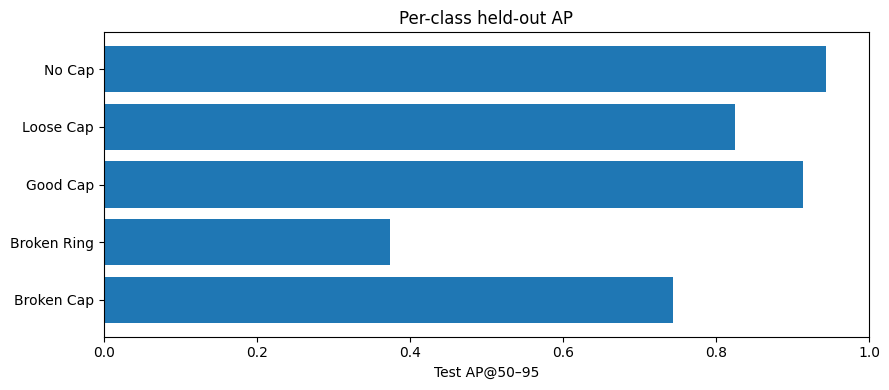

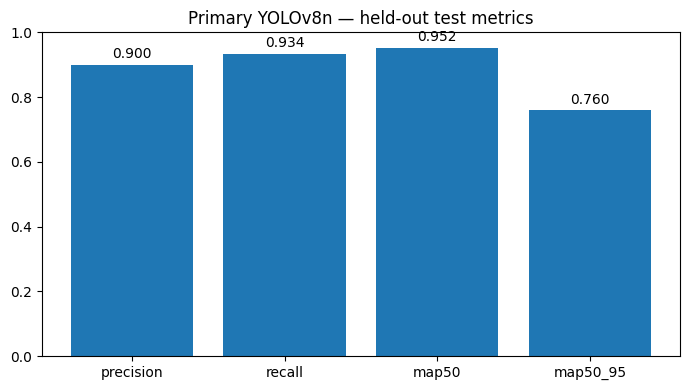

In [10]:
per_class=pd.DataFrame({'class':PRIMARY_NAMES,'boxes_in_source':[primary_audit['box_counts'].get(c,0) for c in PRIMARY_NAMES], 'heldout_map50_95':[metrics_test['per_class_map50_95'][c] for c in PRIMARY_NAMES]})
per_class.to_csv(REPORT/'primary_per_class.csv',index=False)
display(per_class)
fig,ax=plt.subplots(figsize=(9,4));ax.barh(per_class['class'],per_class['heldout_map50_95']);ax.set_xlim(0,1);ax.set_xlabel('Test AP@50–95');ax.set_title('Per-class held-out AP')
fig.tight_layout();fig.savefig(PLOTS/'heldout_per_class_ap.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(7,4));keys=['precision','recall','map50','map50_95'];vals=[metrics_test[k] for k in keys];ax.bar(keys,vals);ax.set_ylim(0,1);ax.set_title('Primary YOLOv8n — held-out test metrics')
for i,v in enumerate(vals):ax.text(i,v+.02,f'{v:.3f}',ha='center');
fig.tight_layout();fig.savefig(PLOTS/'heldout_summary.png',dpi=160);plt.show()

## 10 · Qualitative inference on true test images
Use real test images to inspect false positives and missed/ambiguous cap defects. Images are for demonstration, **not** a replacement for the quantitative held-out evaluation.

In [11]:
test_images=[str(p) for p in sorted(PRIMARY['splits']['test'].iterdir()) if p.is_file() and p.suffix.lower() in IMAGE_EXT]
selected=test_images[:CFG['max_examples']]
if selected:
    inference=best_model.predict(source=selected,conf=CFG['test_conf'],imgsz=CFG['imgsz'],device=DEVICE,save=True,project=str(RUNS),name='primary_test_previews',exist_ok=True,verbose=False)
    prediction_inventory=[]
    for result in inference:
        prediction_inventory.append({'file':Path(result.path).name,'detections':len(result.boxes),'class_ids':[int(x) for x in result.boxes.cls.cpu().tolist()]})
    (REPORT/'qualitative_prediction_inventory.json').write_text(json.dumps(prediction_inventory,indent=2))
    print('Preview run:',RUNS/'primary_test_previews')
else:print('No source test images; no preview generated')

Results saved to /kaggle/working/bottlecap_day23/runs/primary_test_previews
Preview run: /kaggle/working/bottlecap_day23/runs/primary_test_previews


## 11 · Optional packaging experiment (separate ontology, disabled by default)
The secondary archive has a different 4-class target. It must **not** be used to increase primary dataset size without verified remapping and source agreement. You may enable `CFG['secondary_train']=True` only after a passing annotation + leakage audit, verified train/val/test, and source license review. The resulting metrics stay in separate reports.

In [12]:
secondary_metrics=None
if CFG['secondary_train']:
    if SECONDARY is None:raise RuntimeError('Secondary source not uniquely discovered')
    if secondary_audit['invalid_count'] or secondary_audit['cross_split_exact_duplicate_hash_count']:
        raise RuntimeError('Secondary source fails structure or exact leakage audits; training prohibited')
    if secondary_rows is None:raise RuntimeError('Missing secondary manifest')
    groups=secondary_rows.groupby(secondary_rows['stem'].map(image_family))['split'].agg(lambda x:len(set(x)))
    if (groups>1).any():raise RuntimeError('Secondary cross-split image-family collisions; training prohibited')
    if not all(SECONDARY['splits'][s] is not None for s in ('train','valid','test')):
        raise RuntimeError('Secondary must have train/valid/test')
    s_yaml=make_yaml(SECONDARY,OUT/'secondary_data.yaml')
    sm=YOLO(CFG['model'])
    sr=sm.train(data=str(s_yaml),epochs=CFG['secondary_epochs'],patience=CFG['patience'],imgsz=CFG['imgsz'],batch=CFG['batch'],workers=CFG['workers'],device=DEVICE,seed=SEED,project=str(RUNS),name='secondary_packaging_yolov8n',exist_ok=True,plots=True)
    sb=Path(sr.save_dir)/'weights'/'best.pt'
    if not sb.exists():raise FileNotFoundError('Secondary checkpoint missing')
    shutil.copy2(sb,MODELS/'packaging_secondary_best.pt')
    sv=YOLO(str(sb)).val(data=str(s_yaml),split='test',imgsz=CFG['imgsz'],device=DEVICE,project=str(RUNS),name='secondary_final_test',exist_ok=True)
    secondary_metrics={'classes':SECONDARY_NAMES,'precision':float(sv.box.mp),'recall':float(sv.box.mr),'map50':float(sv.box.map50),'map50_95':float(sv.box.map)}
    (REPORT/'secondary_heldout_metrics.json').write_text(json.dumps(secondary_metrics,indent=2))
    print('Secondary test:',secondary_metrics)
else:
    print('Secondary 4-class dataset audited only. This is deliberate and scientifically safer than mixing label spaces.')

Secondary 4-class dataset audited only. This is deliberate and scientifically safer than mixing label spaces.


## 12 · Model export (safe optional ONNX)
ONNX is an inference artifact, **not** proof of deployment accuracy. Export can fail because of dependency/opset/runtime mismatch; checkpoint remains valid. Avoid `SameFileError` by comparing resolved source and destination paths.

In [13]:
export_audit={'attempted':CFG['export_onnx'],'status':'skipped'}
if CFG['export_onnx']:
    try:
        exported=Path(str(best_model.export(format='onnx',imgsz=CFG['imgsz'],simplify=False,opset=12)))
        if not exported.is_file():raise FileNotFoundError(exported)
        dst=MODELS/'bottlecap_primary_best.onnx'
        if exported.resolve()!=dst.resolve():shutil.copy2(exported,dst)
        export_audit={'attempted':True,'status':'success','source':str(exported),'model':str(dst),'bytes':dst.stat().st_size}
        print('ONNX exported:',dst)
    except Exception as e:
        export_audit={'attempted':True,'status':'failed_optional','error':repr(e)}
        print('Optional export failed:',repr(e))
(REPORT/'onnx_export_audit.json').write_text(json.dumps(export_audit,indent=2))

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/kaggle/working/bottlecap_day23/models/bottlecap_primary_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 9, 8400) (6.2 MB)

ONNX: starting export with onnx 1.22.0 opset 12...
ONNX: export success ✅ 0.8s, saved as '/kaggle/working/bottlecap_day23/models/bottlecap_primary_best.onnx' (12.2 MB)

Export complete (1.0s)
Results saved to /kaggle/working/bottlecap_day23/models/bottlecap_primary_best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/bottlecap_day23/models/bottlecap_primary_best.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/bottlecap_day23/models/bottlecap_primary_best.onnx imgsz=

230

## 13 · Final claims, report manifest, and artifact ZIP
The final summary contains only executed measurements. Include audit JSON/CSVs, plots, weight files, YAML and short README; **do not bundle raw datasets**, both for space and licensing. If upstream training fails, this cell naturally fails rather than creating fabricated results.

In [14]:
import zipfile
assert (MODELS/'bottlecap_primary_best.pt').is_file(), 'No primary checkpoint; do not release'
assert (REPORT/'primary_heldout_metrics.json').is_file(), 'No heldout metrics; do not release'
summary={'project':'BottleCap Checker','day':23,'task':'5-class object detection','primary_source':str(PRIMARY['source_yaml']),
         'primary_classes':PRIMARY_NAMES,'dataset_counts':primary_audit['split_images'],
         'source_label_count':primary_audit['box_counts'],'source_audit':{'invalid':primary_audit['invalid_count'],'exact_cross_split_hashes':primary_audit['cross_split_exact_duplicate_hash_count'],'cross_split_filename_families':len(cross_family)},
         'checkpoint_selection':'Ultralytics best.pt selected on source validation only','validation':metrics_val,'heldout_test':metrics_test,
         'secondary':secondary_metrics or 'audited only; different four-class ontology', 'onnx':export_audit,
         'limitations':['Published train/valid/test splits and classes retained; no image-level similarity benchmark beyond filename-family and exact hashes.',
                        'Near-identical images with different names or crops can evade leakage audits.',
                        'mAP is object detection quality, not factory-grade QA pass probability.',
                        'Pretrained YOLO model, one architecture and one seed; no external factory-domain validation.',
                        'Source Roboflow export says CC BY 4.0; attribute dataset authors and verify secondary dataset rights independently.']}
(REPORT/'final_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
readme="# BottleCap Checker Day 23 — Research artifacts\nPrimary task: 5-class YOLOv8n object detection on Bottle Defects v28. Classes: Broken Cap, Broken Ring, Good Cap, Loose Cap, No Cap. Training and checkpoint selection used published train/validation; one-time final evaluation used source test. See `reports/final_summary.json` for executed scores, `reports/primary_audit.json` for data integrity and `reports/primary_family_audit.json` for known leakage risks. Secondary packaging source has a different ontology and is not automatically combined. All results are research prototypes; no commercial production assurance. Raw datasets excluded.\n"
(OUT/'README.md').write_text(readme)
release=Path('/kaggle/working/BottleCap_Day23_Research_Artifacts.zip')
with zipfile.ZipFile(release,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=3,allowZip64=True) as z:
    for folder in (REPORT,PLOTS,MODELS):
        for p in sorted(folder.rglob('*')):
            if p.is_file():z.write(p,p.relative_to(OUT).as_posix())
    for p in (OUT/'README.md',PRIMARY_YAML):
        if p.is_file():z.write(p,p.relative_to(OUT).as_posix())
print('RELEASE READY:',release,'MiB:',round(release.stat().st_size/1024**2,2))
print(json.dumps({'test_precision':metrics_test['precision'],'test_recall':metrics_test['recall'],'test_map50':metrics_test['map50'],'test_map50_95':metrics_test['map50_95']},indent=2))

RELEASE READY: /kaggle/working/BottleCap_Day23_Research_Artifacts.zip MiB: 23.37
{
  "test_precision": 0.9002763692809642,
  "test_recall": 0.93376881996345,
  "test_map50": 0.9521119919493113,
  "test_map50_95": 0.7598204984886472
}


## 14 · Research limitations / next development
**Interpretation boundary:** high held-out mAP on Bottle Defects v28 indicates success under **this dataset protocol**, not guaranteed detection on other bottle types, conveyor speeds or factory illumination. An explicit deployment evaluation should separately measure inference latency, calibration, false reject/false accept cost, confidence thresholds, real camera images, and human-in-the-loop QA.

**Next:** manual cross-split visual similarity review → add independently captured real-world test images → benchmark one stronger model only with validation → fixed preprocessing inference API → upload model card, separate dataset citations, and audit notebooks to repository.

**Save Version → Save & Run All:** after initial audit is clean and GPU is enabled. Verify the notebook actually created `BottleCap_Day23_Research_Artifacts.zip` in the Kaggle **Output** panel.